Name: Sania  
CMS ID: 023-24-0277   
Section: H  
GitHub Profile: https://github.com/saniamirani   
Kaggle Profile: https://www.kaggle.com/saniam58   
Dataset: clean_churn.csv   
Dataset Source: Dataset produced after EDA analysis

In [2]:
#task 1,2
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier


df=pd.read_csv("clean_churn.csv")
y=df["Churn"].map({"Yes":1, "No":0})
X=df.drop(columns=["Churn"])
X=pd.get_dummies(X, columns=["gender","Partner","Dependents","PhoneService",
                              "MultipleLines","InternetService","OnlineSecurity","OnlineBackup",
                              "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract",
                              "PaperlessBilling","PaymentMethod"], dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42 , stratify=y)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_test_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_test_pred)
dt_precision = precision_score(y_test, y_test_pred)
dt_recall = recall_score(y_test, y_test_pred)
dt_f1 = f1_score(y_test, y_test_pred)

In [3]:
#task 3
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42 , stratify=y)
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(X_train, y_train)
y_test_pred = rf_model.predict(X_test)

Answer 4: Random Forest uses many Decision Trees and combines their predictions through majority voting. This reduces overfitting and helps the model generalize better to unseen data.

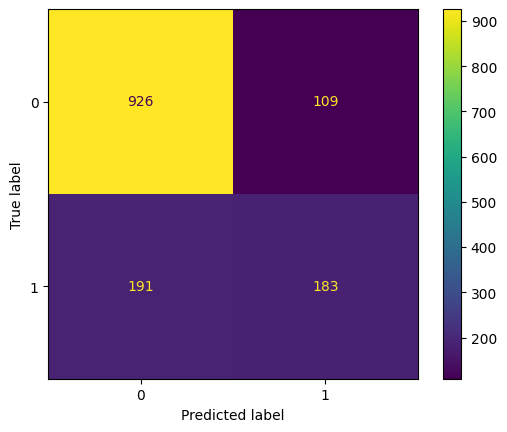

In [4]:
#task 5
rf_accuracy = accuracy_score(y_test, y_test_pred)
rf_precision = precision_score(y_test, y_test_pred)
rf_recall = recall_score(y_test, y_test_pred)
rf_f1 = f1_score(y_test, y_test_pred)

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.show()

In [5]:
#task 6
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Decision Tree": [dt_accuracy, dt_precision, dt_recall, dt_f1],
    "Random Forest": [rf_accuracy, rf_precision, rf_recall, rf_f1]
})
print(comparison)

      Metric  Decision Tree  Random Forest
0   Accuracy       0.719659       0.787083
1  Precision       0.473008       0.626712
2     Recall       0.491979       0.489305
3   F1-Score       0.482307       0.549550


#task 7   
Random Forest performs better overall. It has higher accuracy, precision, and F1-score. The improvement is noticeable, especially in precision and F1, while recall is almost the same.
Because there is class imbalance F1-score matters more than accuracy because it balances precision and recall.

In [7]:
#task 8
dt_cv = cross_val_score(
    dt_model, X, y,
    cv=5,
    scoring="f1"
)

rf_cv = cross_val_score(
    rf_model, X, y,
    cv=5,
    scoring="f1"
)

print("Decision Tree CV F1")
print("Scores:", dt_cv)
print("Mean :", dt_cv.mean())
print("Std  :", dt_cv.std())

print("\nRandom Forest CV F1")
print("Scores:", rf_cv)
print("Mean :", rf_cv.mean())
print("Std  :", rf_cv.std())

Decision Tree CV F1
Scores: [0.47619048 0.51436031 0.49154746 0.45783133 0.49399199]
Mean : 0.48678431367319436
Std  : 0.01889750711658225

Random Forest CV F1
Scores: [0.56661562 0.55235205 0.50974513 0.55485893 0.56145675]
Mean : 0.5490056966067833
Std  : 0.020258277118916847


#task 9   
Random Forest performs better, with a mean F1 of 0.5490 compared with 0.4868 for Decision Tree. The difference is consistent across all five folds, increasing confidence that Random Forest generalizes better rather than the result being caused by one particular train/test split.

In [10]:
#task 10
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the scor

In [11]:
#task 11
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

Best CV F1 Score:
0.5744532996926232


In [12]:
#task 12
tuned_rf = grid_search.best_estimator_

tuned_pred = tuned_rf.predict(X_test)

tuned_accuracy = accuracy_score(y_test, tuned_pred)
tuned_precision = precision_score(y_test, tuned_pred)
tuned_recall = recall_score(y_test, tuned_pred)
tuned_f1 = f1_score(y_test, tuned_pred)

print("Tuned Random Forest")
print("Accuracy :", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall   :", tuned_recall)
print("F1 Score :", tuned_f1)

Tuned Random Forest
Accuracy : 0.8062455642299503
Precision: 0.67003367003367
Recall   : 0.5320855614973262
F1 Score : 0.5931445603576752


In [13]:
#task 13
final_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        tuned_accuracy
    ],
    "Precision": [
        dt_precision,
        rf_precision,
        tuned_precision
    ],
    "Recall": [
        dt_recall,
        rf_recall,
        tuned_recall
    ],
    "F1 Score": [
        dt_f1,
        rf_f1,
        tuned_f1
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.719659,0.473008,0.491979,0.482307
1,Random Forest,0.787083,0.626712,0.489305,0.549550
2,Tuned Random Forest,0.806246,0.670034,0.532086,0.593145


#task 14  
I selected the Tuned Random Forest because it has the highest F1-score (0.5931), along with the highest precision (0.6700), recall (0.5321), and accuracy (0.8062). These improvements over the default Random Forest indicate better performance on the test set, particularly for the imbalanced churn classes.

In [16]:
#task 15
importances = tuned_rf.feature_importances_

feature_importance = pd.Series(
    importances,
    index=X.columns
).sort_values(ascending=False)

feature_importance.head(10)

tenure                            0.148127
TotalCharges                      0.120379
Contract_Month-to-month           0.093459
MonthlyCharges                    0.084836
OnlineSecurity_No                 0.055085
TechSupport_No                    0.047718
InternetService_Fiber optic       0.047263
PaymentMethod_Electronic check    0.040489
Contract_Two year                 0.029719
InternetService_DSL               0.020474
dtype: float64

_The top features are tenure, TotalCharges, Contract_Month-to-month, MonthlyCharges, and OnlineSecurity_No. They generally agree with Lab 2 and Lab 3: tenure, contract, and MonthlyCharges were previously identified as important, while TotalCharges also appeared in Lab 3. The main difference is that the Random Forest distributes importance more broadly across features instead of concentrating heavily on Contract_Month-to-month._

In [20]:
#task 16
final_model = tuned_rf
final_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "customerID": df.index[:len(final_predictions)],
    "Churn": final_predictions
})
submission["Churn"] = submission["Churn"].map({
    0: "No",
    1: "Yes"
})
submission.head()
submission.to_csv("submission.csv", index=False)
print("submission.csv created successfully.")

submission.csv created successfully.


#task 17   
I finally chose the Tuned Random Forest because it achieved the best overall performance, with an accuracy of 80.62% and an F1 score of 59.31%. Compared with the Decision Tree from Lab 3, it performed better in accuracy, precision, recall, and F1 score. However, its recall of 53.21% shows that it still misses some churn cases. The model may also be affected by the quality of the data and selected features. Overall, the Tuned Random Forest is a stronger model for this churn prediction task.

#task 18   
If I had more time, I would try other algorithms such as XGBoost or Gradient Boosting and perform deeper hyperparameter tuning. I would also handle the class imbalance using techniques such as class weights. Finally, I would use cross-validation to make the model evaluation more reliable and compare the results again.